In [1]:
import pandas as pd
df = pd.read_csv('gossipcop_bal.csv')
from sklearn.model_selection import train_test_split
X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['title'], 
    df['label'],            
    test_size=0.2,               
    random_state=42,               
)

In [2]:
print("Train Samples:", len(X_train_text))
print("Test Samples :", len(X_test_text))

Train Samples: 8323
Test Samples : 2081


Device: cuda

EXTRACTING BERT EMBEDDINGS

Extracting Train Embeddings...


Generating BERT Embeddings:   0%|          | 0/521 [00:00<?, ?it/s]


Extracting Test Embeddings...


Generating BERT Embeddings:   0%|          | 0/131 [00:00<?, ?it/s]


Train Shape: (8323, 768)
Test Shape : (2081, 768)

MODEL SELECTION WITH PROPER 5-FOLD CV (BERT)

Tuning: Logistic Regression
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Params: {'C': 0.1}
CV Accuracy: 0.7486
CV Precision: 0.7506
CV Recall: 0.7400
CV F1: 0.7453


Tuning: SVM Linear
Fitting 5 folds for each of 5 candidates, totalling 25 fits
Best Params: {'C': 0.1}
CV Accuracy: 0.7405
CV Precision: 0.7446
CV Recall: 0.7270
CV F1: 0.7357


Tuning: SVM RBF
Fitting 5 folds for each of 12 candidates, totalling 60 fits
Best Params: {'C': 5, 'gamma': 'scale'}
CV Accuracy: 0.7579
CV Precision: 0.7636
CV Recall: 0.7427
CV F1: 0.7530


Tuning: Random Forest
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Params: {'max_depth': 10, 'n_estimators': 200}
CV Accuracy: 0.7301
CV Precision: 0.7374
CV Recall: 0.7096
CV F1: 0.7232


MODEL RANKING
              Model                            Best Params  CV Accuracy  CV Precision  CV Recall  CV F1
            SVM RB

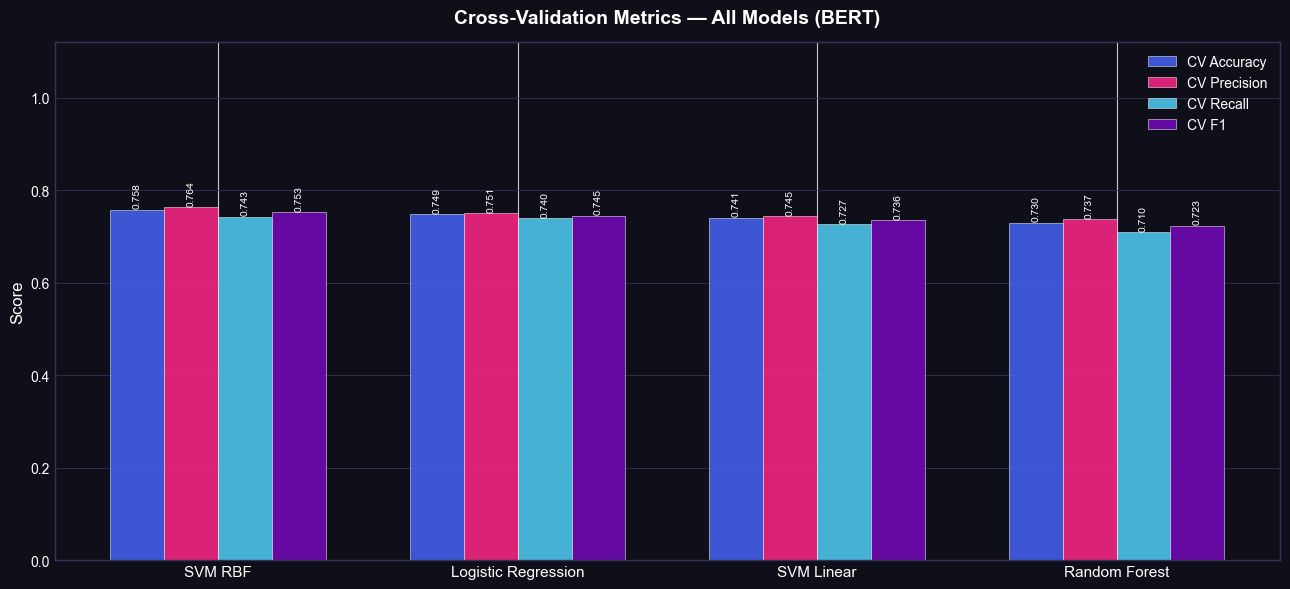

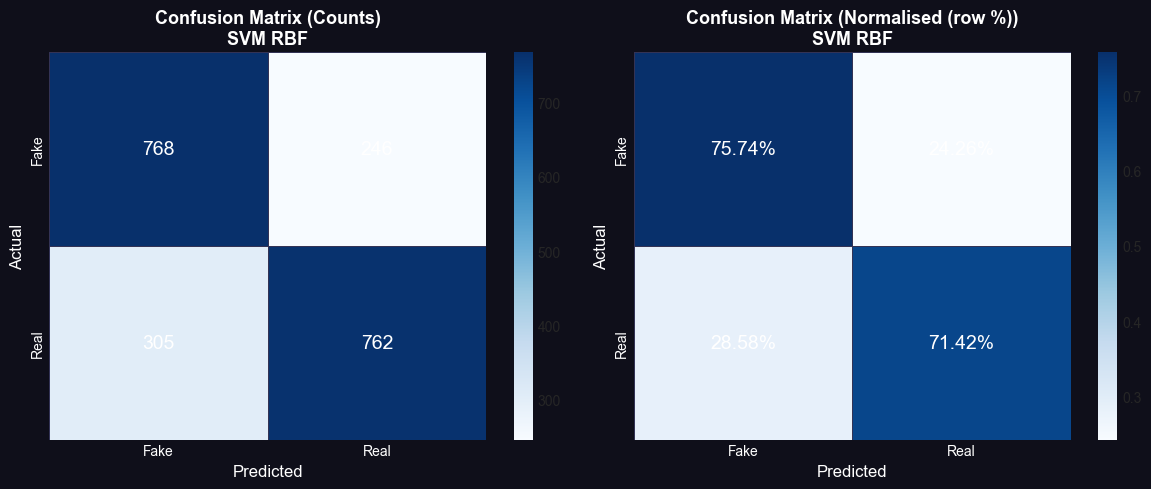

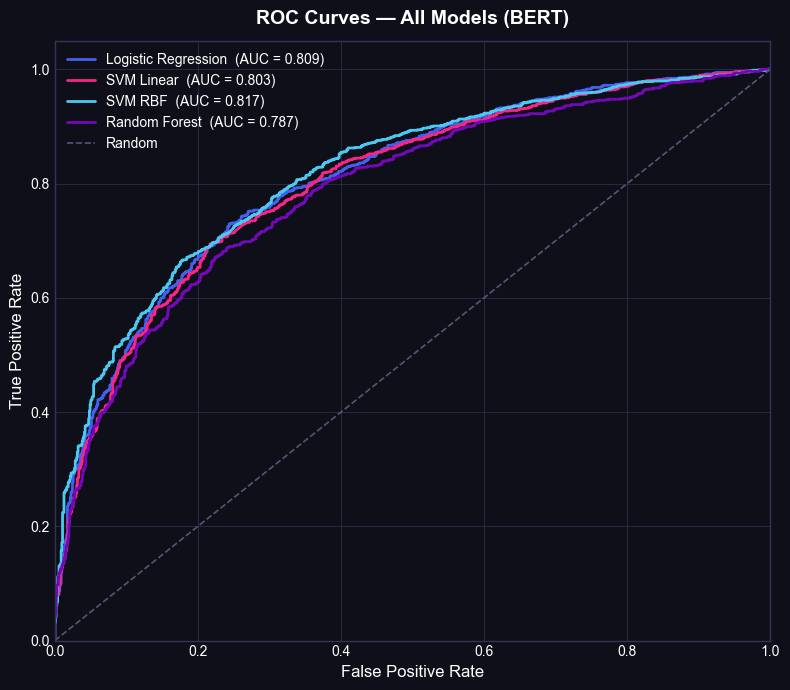

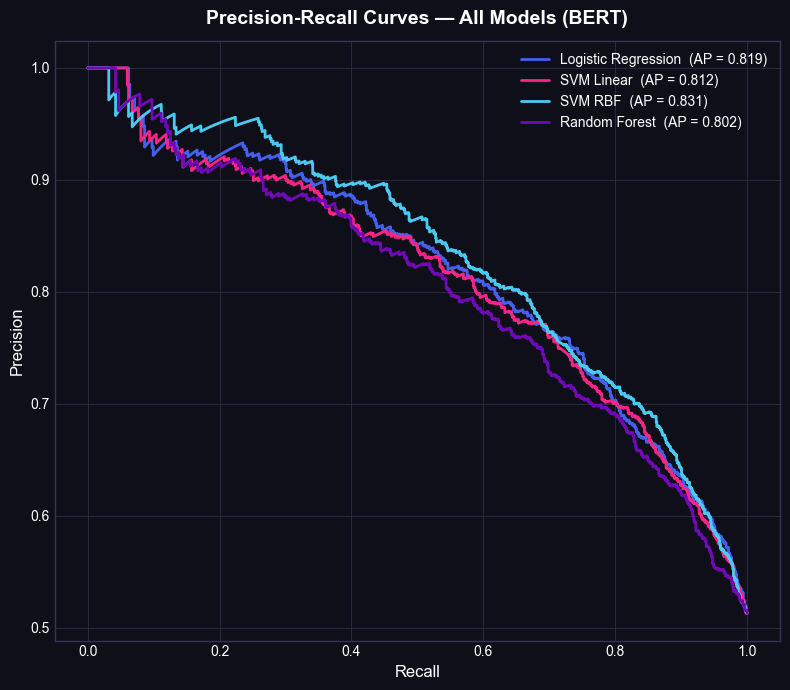

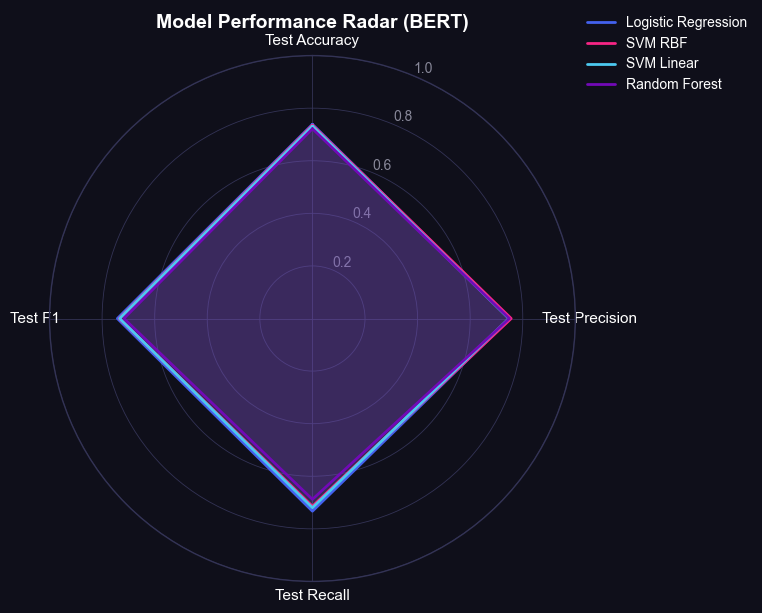

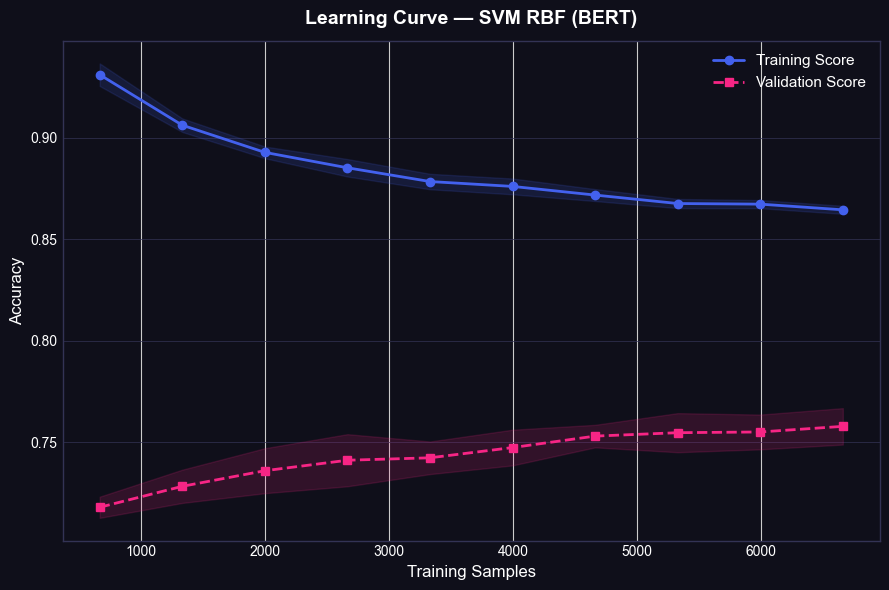

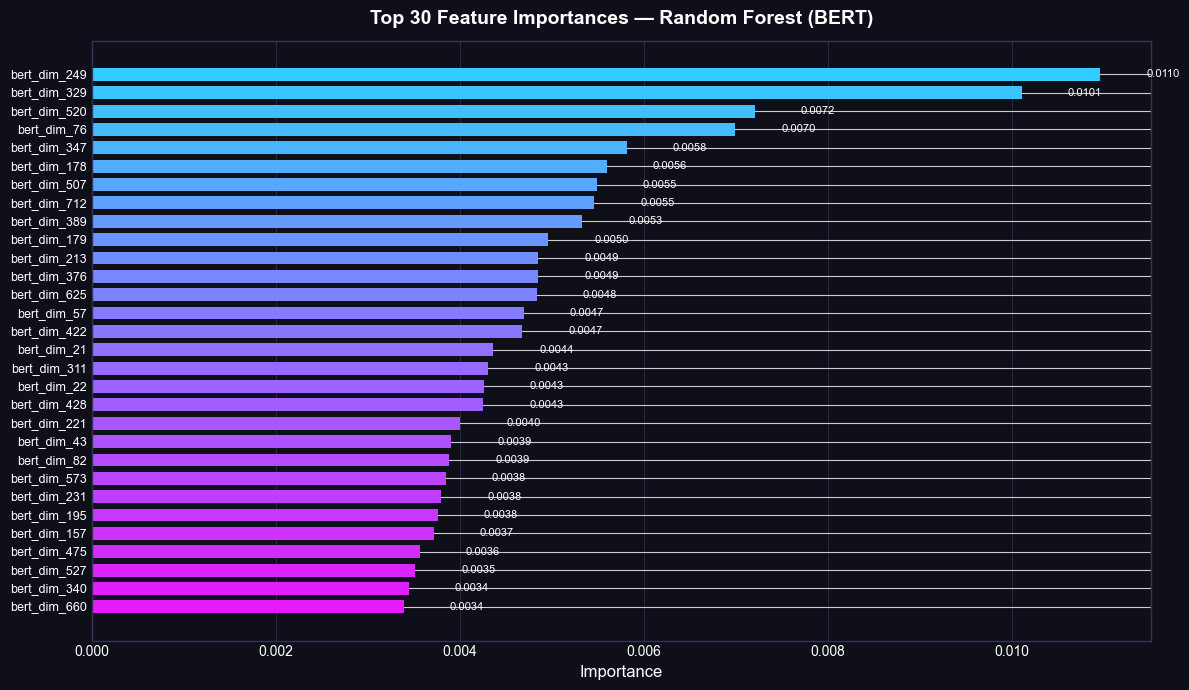

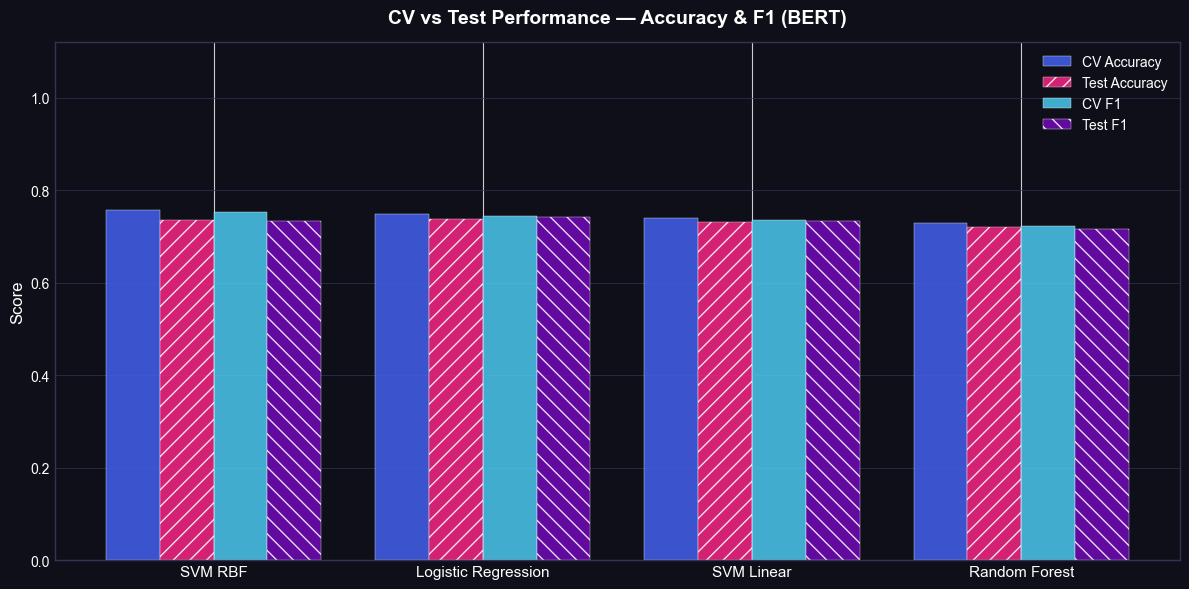

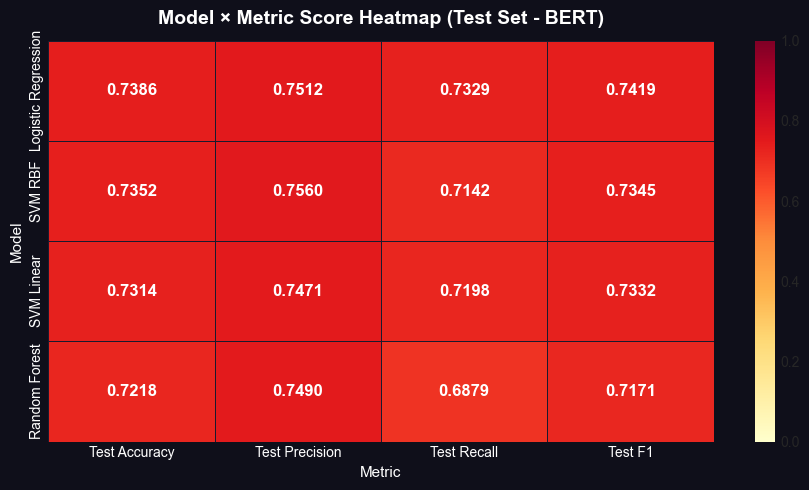

In [3]:
# ==========================================================
# BERT-Base + Hyperparameter Tuning Pipeline
# WITH ADVANCED VISUALIZATIONS
# ==========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, learning_curve
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
import torch
from torch.utils.data import Dataset, DataLoader
from transformers import BertTokenizer, BertModel

# ----------------------------------------------------------
# PLOT STYLE
# ----------------------------------------------------------
plt.style.use("seaborn-v0_8-whitegrid")
PALETTE = ["#4361EE", "#F72585", "#4CC9F0", "#7209B7", "#3A0CA3"]
sns.set_palette(PALETTE)

# ----------------------------------------------------------
# LOAD BERT
# ----------------------------------------------------------
tokenizer = BertTokenizer.from_pretrained("bert-base-uncased")
bert_model = BertModel.from_pretrained("bert-base-uncased")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

bert_model.to(device)
bert_model.eval()

print("Device:", device)

# ----------------------------------------------------------
# DATASET CLASS
# ----------------------------------------------------------
class TextDataset(Dataset):

    def __init__(self, texts, tokenizer, max_len=128):
        self.texts = texts.tolist()
        self.tokenizer = tokenizer
        self.max_len = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):

        text = str(self.texts[idx])

        encoding = self.tokenizer(
            text,
            truncation=True,
            padding="max_length",
            max_length=self.max_len,
            return_tensors="pt"
        )

        return {
            "input_ids": encoding["input_ids"].squeeze(0),
            "attention_mask": encoding["attention_mask"].squeeze(0)
        }

# ----------------------------------------------------------
# FUNCTION TO EXTRACT BERT EMBEDDINGS
# ----------------------------------------------------------
def get_bert_embeddings(texts, batch_size=16):

    dataset = TextDataset(texts, tokenizer)
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False)

    embeddings = []

    with torch.no_grad():

        for batch in tqdm(loader, desc="Generating BERT Embeddings"):

            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)

            outputs = bert_model(
                input_ids=input_ids,
                attention_mask=attention_mask
            )

            # CLS token embedding
            cls_embedding = outputs.last_hidden_state[:, 0, :]

            embeddings.append(cls_embedding.cpu().numpy())

    return np.vstack(embeddings)

# ----------------------------------------------------------
# HELPER: save figure
# ----------------------------------------------------------
def save_fig(fig, filename, dpi=150):
    fig.savefig(filename, dpi=dpi, bbox_inches="tight", facecolor=fig.get_facecolor())
    print(f"  [Saved] {filename}")

# ----------------------------------------------------------
# PLOT 1 – Cross-Validation Metric Comparison
# ----------------------------------------------------------
def plot_cv_metrics(df_results):
    metrics = ["CV Accuracy", "CV Precision", "CV Recall", "CV F1"]
    models  = df_results["Model"].tolist()
    x       = np.arange(len(models))
    width   = 0.18

    fig, ax = plt.subplots(figsize=(13, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for i, (metric, color) in enumerate(zip(metrics, PALETTE)):
        vals = df_results[metric].values
        bars = ax.bar(x + i * width, vals, width, label=metric,
                      color=color, alpha=0.88, edgecolor="white", linewidth=0.4)
        for bar, val in zip(bars, vals):
            ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.003,
                    f"{val:.3f}", ha="center", va="bottom",
                    fontsize=7.5, color="white", rotation=90)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(models, color="white", fontsize=11)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score", color="white", fontsize=12)
    ax.set_title("Cross-Validation Metrics — All Models (BERT)", color="white",
                 fontsize=14, fontweight="bold", pad=14)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)
    ax.yaxis.grid(True, color="#333355", linewidth=0.6)

    fig.tight_layout()
    save_fig(fig, "bert_cv_metrics_comparison_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 2 – Confusion Matrix (best model)
# ----------------------------------------------------------
def plot_confusion_matrix(y_true, y_pred, model_name, class_names=("Fake", "Real")):
    cm   = confusion_matrix(y_true, y_pred)
    norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5), facecolor="#0F0F1A")

    for ax, data, title, fmt in zip(
        axes,
        [cm, norm],
        ["Counts", "Normalised (row %)"],
        ["d", ".2%"]
    ):
        ax.set_facecolor("#0F0F1A")
        sns.heatmap(
            data, annot=True, fmt=fmt, ax=ax,
            cmap="Blues", linewidths=0.5, linecolor="#333355",
            xticklabels=class_names, yticklabels=class_names,
            annot_kws={"size": 14, "color": "white"}
        )
        ax.set_xlabel("Predicted", color="white", fontsize=12)
        ax.set_ylabel("Actual",    color="white", fontsize=12)
        ax.set_title(f"Confusion Matrix ({title})\n{model_name}",
                     color="white", fontsize=13, fontweight="bold")
        ax.tick_params(colors="white")
        for spine in ax.spines.values():
            spine.set_edgecolor("#333355")

    fig.tight_layout()
    save_fig(fig, f"bert_confusion_matrix_{model_name.replace(' ', '_')}_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 3 – ROC Curves (all models)
# ----------------------------------------------------------
def plot_roc_curves(best_models, X_test, y_test):
    fig, ax = plt.subplots(figsize=(8, 7), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for (name, model), color in zip(best_models.items(), PALETTE):
        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
        else:
            continue
        fpr, tpr, _ = roc_curve(y_test, scores)
        roc_auc     = auc(fpr, tpr)
        ax.plot(fpr, tpr, color=color, lw=2,
                label=f"{name}  (AUC = {roc_auc:.3f})")

    ax.plot([0, 1], [0, 1], "--", color="#555577", lw=1.2, label="Random")
    ax.set_xlim([0.0, 1.0])
    ax.set_ylim([0.0, 1.05])
    ax.set_xlabel("False Positive Rate", color="white", fontsize=12)
    ax.set_ylabel("True Positive Rate",  color="white", fontsize=12)
    ax.set_title("ROC Curves — All Models (BERT)", color="white",
                 fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.xaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "bert_roc_analysis_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 4 – Precision-Recall Curves (all models)
# ----------------------------------------------------------
def plot_pr_curves(best_models, X_test, y_test):
    fig, ax = plt.subplots(figsize=(8, 7), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for (name, model), color in zip(best_models.items(), PALETTE):
        if hasattr(model, "predict_proba"):
            scores = model.predict_proba(X_test)[:, 1]
        elif hasattr(model, "decision_function"):
            scores = model.decision_function(X_test)
        else:
            continue
        prec, rec, _ = precision_recall_curve(y_test, scores)
        ap           = average_precision_score(y_test, scores)
        ax.plot(rec, prec, color=color, lw=2,
                label=f"{name}  (AP = {ap:.3f})")

    ax.set_xlabel("Recall",    color="white", fontsize=12)
    ax.set_ylabel("Precision", color="white", fontsize=12)
    ax.set_title("Precision-Recall Curves — All Models (BERT)", color="white",
                 fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.xaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "bert_precision_recall_curves_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 5 – Test-Set Metrics Radar Chart
# ----------------------------------------------------------
def plot_radar(comparison_df):
    metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
    n_metrics = len(metrics)
    angles   = np.linspace(0, 2 * np.pi, n_metrics, endpoint=False).tolist()
    angles  += angles[:1]

    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw={"polar": True},
                           facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)
    ax.set_xticks(angles[:-1])
    ax.set_xticklabels(metrics, color="white", fontsize=11)
    ax.yaxis.set_tick_params(labelcolor="#888899")
    ax.set_ylim(0, 1)
    ax.spines["polar"].set_color("#333355")
    ax.yaxis.grid(color="#333355", linewidth=0.6)
    ax.xaxis.grid(color="#333355", linewidth=0.6)

    for (_, row), color in zip(comparison_df.iterrows(), PALETTE):
        vals  = row[metrics].tolist() + row[metrics].tolist()[:1]
        ax.plot(angles, vals, color=color, lw=2, label=row["Model"])
        ax.fill(angles, vals, color=color, alpha=0.12)

    ax.set_title("Model Performance Radar (BERT)", color="white",
                 fontsize=14, fontweight="bold", pad=20)
    ax.legend(loc="upper right", bbox_to_anchor=(1.35, 1.1),
              framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "bert_performance_radar_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 6 – Learning Curve (best model)
# ----------------------------------------------------------
def plot_learning_curve(model, X_train, y_train, model_name):
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_train, y_train,
        cv=skf, scoring="accuracy",
        train_sizes=np.linspace(0.1, 1.0, 10),
        n_jobs=-1
    )

    train_mean = train_scores.mean(axis=1)
    train_std  = train_scores.std(axis=1)
    val_mean   = val_scores.mean(axis=1)
    val_std    = val_scores.std(axis=1)

    fig, ax = plt.subplots(figsize=(9, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    ax.plot(train_sizes, train_mean, "o-", color=PALETTE[0], lw=2, label="Training Score")
    ax.fill_between(train_sizes,
                    train_mean - train_std,
                    train_mean + train_std,
                    alpha=0.15, color=PALETTE[0])

    ax.plot(train_sizes, val_mean, "s--", color=PALETTE[1], lw=2, label="Validation Score")
    ax.fill_between(train_sizes,
                    val_mean - val_std,
                    val_mean + val_std,
                    alpha=0.15, color=PALETTE[1])

    ax.set_xlabel("Training Samples", color="white", fontsize=12)
    ax.set_ylabel("Accuracy",         color="white", fontsize=12)
    ax.set_title(f"Learning Curve — {model_name} (BERT)", color="white",
                 fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=11)

    fig.tight_layout()
    save_fig(fig, f"bert_learning_curve_{model_name.replace(' ', '_')}_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 7 – Feature Importances (Random Forest only)
# ----------------------------------------------------------
def plot_feature_importance(rf_model, feature_names, top_n=30):
    importances = rf_model.feature_importances_
    idx         = np.argsort(importances)[::-1][:top_n]
    top_feats   = np.array(feature_names)[idx]
    top_vals    = importances[idx]

    fig, ax = plt.subplots(figsize=(12, 7), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    colors = plt.cm.cool(np.linspace(0.2, 0.9, top_n))
    bars   = ax.barh(range(top_n), top_vals[::-1], color=colors[::-1],
                     edgecolor="none", height=0.7)

    ax.set_yticks(range(top_n))
    ax.set_yticklabels(top_feats[::-1], color="white", fontsize=9)
    ax.set_xlabel("Importance", color="white", fontsize=12)
    ax.set_title(f"Top {top_n} Feature Importances — Random Forest (BERT)",
                 color="white", fontsize=14, fontweight="bold", pad=12)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.xaxis.grid(True, color="#333355", linewidth=0.5)

    for bar, val in zip(bars, top_vals[::-1]):
        ax.text(val + 0.0005, bar.get_y() + bar.get_height() / 2,
                f"{val:.4f}", va="center", color="white", fontsize=8)

    fig.tight_layout()
    save_fig(fig, "bert_feature_importance_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 8 – CV vs Test Score Comparison
# ----------------------------------------------------------
def plot_cv_vs_test(df_results, comparison_df):
    merged = pd.merge(
        df_results[["Model", "CV Accuracy", "CV F1"]],
        comparison_df[["Model", "Test Accuracy", "Test F1"]],
        on="Model"
    )

    x     = np.arange(len(merged))
    width = 0.2

    fig, ax = plt.subplots(figsize=(12, 6), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    for i, (col, color, hatch) in enumerate(zip(
        ["CV Accuracy", "Test Accuracy", "CV F1", "Test F1"],
        PALETTE,
        ["", "//", "", "\\\\"]
    )):
        ax.bar(x + i * width, merged[col], width,
               label=col, color=color, alpha=0.85,
               hatch=hatch, edgecolor="white", linewidth=0.3)

    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(merged["Model"], color="white", fontsize=11)
    ax.set_ylim(0, 1.12)
    ax.set_ylabel("Score", color="white", fontsize=12)
    ax.set_title("CV vs Test Performance — Accuracy & F1 (BERT)", color="white",
                 fontsize=14, fontweight="bold", pad=14)
    ax.tick_params(colors="white")
    ax.spines[:].set_color("#333355")
    ax.yaxis.grid(True, color="#333355", linewidth=0.5)
    ax.legend(framealpha=0.2, labelcolor="white", facecolor="#1A1A2E", fontsize=10)

    fig.tight_layout()
    save_fig(fig, "bert_cv_test_comparison_20260130.png")
    return fig

# ----------------------------------------------------------
# PLOT 9 – Heatmap of all model × metric scores
# ----------------------------------------------------------
def plot_score_heatmap(comparison_df):
    metrics = ["Test Accuracy", "Test Precision", "Test Recall", "Test F1"]
    data    = comparison_df.set_index("Model")[metrics]

    fig, ax = plt.subplots(figsize=(9, 5), facecolor="#0F0F1A")
    ax.set_facecolor("#0F0F1A")

    sns.heatmap(
        data, annot=True, fmt=".4f", ax=ax,
        cmap="YlOrRd", linewidths=0.5, linecolor="#1A1A2E",
        annot_kws={"size": 12, "weight": "bold"},
        vmin=0, vmax=1
    )
    ax.set_title("Model × Metric Score Heatmap (Test Set - BERT)",
                 color="white", fontsize=14, fontweight="bold", pad=12)
    ax.set_xlabel("Metric", color="white", fontsize=11)
    ax.set_ylabel("Model",  color="white", fontsize=11)
    ax.tick_params(colors="white")
    for spine in ax.spines.values():
        spine.set_edgecolor("#333355")

    fig.tight_layout()
    save_fig(fig, "bert_model_metric_heatmap_20260130.png")
    return fig

# ----------------------------------------------------------
# EXTRACT TRAIN / TEST EMBEDDINGS
# ----------------------------------------------------------
print("\n" + "="*60)
print("EXTRACTING BERT EMBEDDINGS")
print("="*60)

print("\nExtracting Train Embeddings...")
X_train = get_bert_embeddings(X_train_text)

print("\nExtracting Test Embeddings...")
X_test = get_bert_embeddings(X_test_text)

print("\nTrain Shape:", X_train.shape)
print("Test Shape :", X_test.shape)

# ==========================================================
# MODELS + PARAMETER GRID
# ==========================================================
param_grid = {

    "Logistic Regression": {
        "model": LogisticRegression(
            max_iter=3000,
            random_state=42
        ),
        "params": {
            "C": [0.1, 0.5, 1, 2, 5]
        }
    },

    "SVM Linear": {
        "model": SVC(
            kernel="linear",
            probability=True,
            random_state=42
        ),
        "params": {
            "C": [0.1, 0.5, 1, 2, 5]
        }
    },

    "SVM RBF": {
        "model": SVC(
            kernel="rbf",
            probability=True,
            random_state=42
        ),
        "params": {
            "C": [0.5, 1, 2, 5],
            "gamma": ["scale", "auto", 0.1]
        }
    },

    "Random Forest": {
        "model": RandomForestClassifier(
            random_state=42
        ),
        "params": {
            "n_estimators": [100, 200],
            "max_depth": [None, 10, 20]
        }
    }
}

# ==========================================================
# RESULTS FILE
# ==========================================================
RESULTS_FILE = "bert_model_results_20260130.txt"

open(RESULTS_FILE, "w", encoding="utf-8").close()

def save_to_txt(text=""):
    with open(RESULTS_FILE, "a", encoding="utf-8") as f:
        f.write(str(text) + "\n")

# ==========================================================
# STEP 1: GRID SEARCH WITH 5-FOLD CV
# ==========================================================
header = "="*60
print("\n" + header)
print("MODEL SELECTION WITH PROPER 5-FOLD CV (BERT)")
print(header)

save_to_txt(header)
save_to_txt("MODEL SELECTION WITH PROPER 5-FOLD CV (BERT)")
save_to_txt(header)

results = []
best_models = {}

for model_name, mp in param_grid.items():

    print(f"\nTuning: {model_name}")
    save_to_txt(f"\nTuning: {model_name}")

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    grid = GridSearchCV(
        estimator=mp["model"],
        param_grid=mp["params"],
        cv=skf,
        scoring="accuracy",
        n_jobs=-1,
        verbose=1
    )

    grid.fit(X_train, y_train)

    best_models[model_name] = grid.best_estimator_

    # Get cross-validation metrics
    y_cv_pred = cross_val_predict(
        grid.best_estimator_,
        X_train,
        y_train,
        cv=skf,
        n_jobs=-1
    )

    cv_acc = accuracy_score(y_train, y_cv_pred)
    cv_prec = precision_score(y_train, y_cv_pred, average="binary")
    cv_rec = recall_score(y_train, y_cv_pred, average="binary")
    cv_f1 = f1_score(y_train, y_cv_pred, average="binary")

    results.append({
        "Model": model_name,
        "Best Params": grid.best_params_,
        "CV Accuracy": round(cv_acc, 4),
        "CV Precision": round(cv_prec, 4),
        "CV Recall": round(cv_rec, 4),
        "CV F1": round(cv_f1, 4)
    })

    txt = (
        f"Best Params: {grid.best_params_}\n"
        f"CV Accuracy: {cv_acc:.4f}\n"
        f"CV Precision: {cv_prec:.4f}\n"
        f"CV Recall: {cv_rec:.4f}\n"
        f"CV F1: {cv_f1:.4f}\n"
    )

    print(txt)
    save_to_txt(txt)

# ==========================================================
# STEP 2: RANK MODELS
# ==========================================================
df_results = pd.DataFrame(results)

df_results = df_results.sort_values(
    by="CV Accuracy",
    ascending=False
)

print("\n" + "="*60)
print("MODEL RANKING")
print("="*60)

print(df_results.to_string(index=False))

save_to_txt("\nMODEL RANKING")
save_to_txt(df_results.to_string(index=False))

best_model_name = df_results.iloc[0]["Model"]
best_model = best_models[best_model_name]

selection_text = (
    f"\nSelected Best Model: {best_model_name}"
    f"\nCV Accuracy: {df_results.iloc[0]['CV Accuracy']:.4f}"
)

print(selection_text)
save_to_txt(selection_text)

# ==========================================================
# STEP 3: RETRAIN BEST MODEL ON FULL TRAIN DATA
# ==========================================================
print("\n" + "="*60)
print("RETRAINING BEST MODEL")
print("="*60)

best_model.fit(X_train, y_train)

print("Model Retrained Successfully")
save_to_txt("\nModel Retrained Successfully")

# ==========================================================
# STEP 4: FINAL TEST EVALUATION
# ==========================================================
print("\n" + "="*60)
print("FINAL TEST EVALUATION")
print("="*60)

y_pred = best_model.predict(X_test)

test_accuracy = accuracy_score(y_test, y_pred)
test_precision = precision_score(y_test, y_pred, average="binary")
test_recall = recall_score(y_test, y_pred, average="binary")
test_f1 = f1_score(y_test, y_pred, average="binary")

eval_text = (
    f"\nFinal Test Accuracy : {test_accuracy:.4f}\n"
    f"Final Test Precision: {test_precision:.4f}\n"
    f"Final Test Recall   : {test_recall:.4f}\n"
    f"Final Test F1 Score : {test_f1:.4f}"
)

print(eval_text)
save_to_txt(eval_text)

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

save_to_txt("\nClassification Report:")
save_to_txt(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

save_to_txt("\nConfusion Matrix:")
save_to_txt(str(confusion_matrix(y_test, y_pred)))

# ==========================================================
# STEP 5: COMPARE ALL MODELS ON TEST SET
# ==========================================================
print("\n" + "="*60)
print("COMPARISON OF ALL MODELS ON TEST SET")
print("="*60)

comparison_results = []

for model_name, estimator in best_models.items():

    estimator.fit(X_train, y_train)

    pred = estimator.predict(X_test)

    acc = accuracy_score(y_test, pred)
    prec = precision_score(y_test, pred, average="binary")
    rec = recall_score(y_test, pred, average="binary")
    f1 = f1_score(y_test, pred, average="binary")

    comparison_results.append({
        "Model": model_name,
        "Test Accuracy": round(acc, 4),
        "Test Precision": round(prec, 4),
        "Test Recall": round(rec, 4),
        "Test F1": round(f1, 4)
    })

comparison_df = pd.DataFrame(comparison_results)

comparison_df = comparison_df.sort_values(
    by=["Test F1", "Test Accuracy"],
    ascending=False
)

print(comparison_df.to_string(index=False))
save_to_txt("\nCOMPARISON OF ALL MODELS ON TEST SET")
save_to_txt(comparison_df.to_string(index=False))

# ==========================================================
# STEP 6: BEST MODEL BASED ON TEST SET
# ==========================================================
best_test_model_name = comparison_df.iloc[0]["Model"]
best_test_acc = comparison_df.iloc[0]["Test Accuracy"]
best_test_f1 = comparison_df.iloc[0]["Test F1"]

print("\n" + "="*60)
print("BEST MODEL BASED ON TEST SET")
print("="*60)

print("Best Model     :", best_test_model_name)
print("Test Accuracy  :", best_test_acc)
print("Test F1 Score  :", best_test_f1)

save_to_txt("\nBEST MODEL BASED ON TEST SET")
save_to_txt(f"Best Model: {best_test_model_name}")
save_to_txt(f"Test Accuracy: {best_test_acc}")
save_to_txt(f"Test F1 Score: {best_test_f1}")

# ==========================================================
# STEP 7: GENERATE PLOTS
# ==========================================================
print("\n" + "="*60)
print("GENERATING PLOTS")
print("="*60)
save_to_txt("\nGENERATING PLOTS")

plot_cv_metrics(df_results)

plot_confusion_matrix(
    y_test,
    best_model.predict(X_test),
    best_model_name
)

plot_roc_curves(best_models, X_test, y_test)

plot_pr_curves(best_models, X_test, y_test)

plot_radar(comparison_df)

plot_learning_curve(
    best_model,
    X_train,
    y_train,
    best_model_name
)

if "Random Forest" in best_models:
    rf_model = best_models["Random Forest"]
    feature_names = [f"bert_dim_{i}" for i in range(X_train.shape[1])]
    plot_feature_importance(rf_model, feature_names)

plot_cv_vs_test(df_results, comparison_df)

plot_score_heatmap(comparison_df)

print("\n✓ All plots saved successfully!")
print("="*60)

save_to_txt("\n✓ All plots saved successfully!")
save_to_txt(header)

In [4]:
import pickle

with open("best_bert_embed_gossip_cop.pkl", "wb") as f:
    pickle.dump(best_model, f)

print("Best model saved successfully")

Best model saved successfully
